# Clasificación multietiqueta de radiografías de tórax con redes neuronales convolucionales

## ChestMNIST — TensorFlow/Keras — Metodología CRISP-DM

**Asignatura:** Inteligencia Artificial  
**Integrantes:** Brayan Charry - Julian Narvaez - Jhoiner Puentes

## Objetivo del notebook

Construir y comparar tres arquitecturas de redes neuronales convolucionales —VGG compacta, ResNet compacta y MobileNetV2— para identificar 14 etiquetas de hallazgos torácicos en imágenes de ChestMNIST.

Es un problema multietiqueta: una misma radiografía puede tener varias etiquetas positivas.

Este notebook corresponde a la CNN. La RNA con extracción de características HOG se desarrolla en un Colab independiente.

## Organización del proyecto

| Fase | Contenido |
|---|---|
| 1. Comprensión del negocio | Problema, objetivos, errores y criterios de evaluación |
| 2. Comprensión de los datos | Fuente, particiones, imágenes, etiquetas y calidad |
| 3. Preparación de los datos | Formato de entrada y normalización |
| 4. Modelado | Entrenamiento y comparación de tres arquitecturas |
| 5. Evaluación | Métricas, matrices de confusión y análisis de errores |
| 6. Despliegue | Guardado, demostración, conclusiones y limitaciones |

# FASE 1. Comprensión del negocio

## 1.1 Contexto

La interpretación de radiografías de tórax requiere reconocer diferentes hallazgos que pueden coexistir en una misma imagen. Este proyecto estudia si las redes neuronales convolucionales pueden aprender patrones relacionados con las etiquetas de ChestMNIST.

El alcance es académico: se evalúan modelos sobre imágenes de baja resolución y sus resultados no constituyen un diagnóstico médico.

## 1.2 Problema

¿Qué desempeño alcanzan VGG compacta, ResNet compacta y MobileNetV2 al identificar las 14 etiquetas de ChestMNIST, y qué limitaciones presentan para detectar los casos positivos?

## 1.3 Objetivos

**Objetivo general**

Comparar tres arquitecturas CNN para la clasificación multietiqueta de radiografías de tórax de ChestMNIST.

**Objetivos específicos**

- Explorar las imágenes, las etiquetas y su distribución.
- Verificar la calidad y el formato de los datos.
- Preparar las imágenes conservando su estructura espacial.
- Entrenar las tres arquitecturas con las mismas particiones y tres semillas.
- Seleccionar la arquitectura mediante sus resultados de validación.
- Evaluar el modelo seleccionado con AUC, precisión, recall, F1 y matrices de confusión por etiqueta.
- Comparar posteriormente sus resultados con la RNA basada en HOG, utilizando el mismo conjunto de prueba.

## 1.4 Significado de los errores

Los errores se interpretan por separado para cada etiqueta.

| Resultado | Significado |
|---|---|
| Verdadero positivo | La etiqueta está presente y el modelo la identifica |
| Falso negativo | La etiqueta está presente y el modelo no la identifica |
| Falso positivo | El modelo identifica una etiqueta que no está registrada |
| Verdadero negativo | La etiqueta no está registrada y el modelo predice su ausencia |

El recall permite medir qué proporción de los positivos registrados se detecta. La precisión muestra qué proporción de las predicciones positivas coincide con las etiquetas del dataset.

## 1.5 Criterios de evaluación

- La arquitectura se seleccionará por la mayor AUC-ROC macro media en validación entre las tres semillas.
- Se reportará la variación entre semillas para describir la estabilidad de cada arquitectura.
- La evaluación final incluirá métricas por etiqueta y promedios macro y micro.
- Se comparará el desempeño con una línea base que predice ausencia en todas las etiquetas.
- La exactitud binaria se interpretará junto con recall y F1, porque puede ser elevada cuando predominan las etiquetas negativas.
- Cualquier ajuste de umbral se decidirá con validación antes de evaluar en prueba.

Estos criterios permiten evaluar el aprendizaje y sus limitaciones; no representan requisitos de validación clínica.

## 1.6 Restricciones

- Las imágenes tienen una resolución de 28 × 28 píxeles.
- Las frecuencias de las etiquetas pueden ser diferentes y deben analizarse.
- Se respetan las particiones oficiales de entrenamiento, validación y prueba.
- Las decisiones sobre modelos y umbrales se toman con validación.
- El conjunto de prueba se reserva para la evaluación final.
- Las conclusiones se redactarán a partir de los resultados obtenidos en este proyecto.

# FASE 2. Comprensión de los datos

### 2.0 Carga de las particiones oficiales

In [3]:
!pip install medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 7.2 MB/s eta 0:00:00


In [26]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

from medmnist import ChestMNIST

print("Versión de TensorFlow:", tf.__version__)
print("GPU disponibles:", tf.config.list_physical_devices('GPU'))

Versión de TensorFlow: 2.21.0
GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2.1. Carga de los datos

Cargamos los tres conjuntos oficiales de ChestMNIST:

- Entrenamiento: para ajustar los pesos del modelo.
- Validación: para observar su comportamiento durante el entrenamiento.
- Prueba: para realizar la evaluación final.

Conservamos las 14 etiquetas binarias de cada imagen.

In [5]:
# Cargar los conjuntos oficiales
train_dataset = ChestMNIST(split='train', download=True)
val_dataset = ChestMNIST(split='val', download=True)
test_dataset = ChestMNIST(split='test', download=True)

# Obtener imágenes
X_train_full = train_dataset.imgs
X_val_full = val_dataset.imgs
X_test_full = test_dataset.imgs

# Obtener etiquetas
y_train_cnn = train_dataset.labels.copy()
y_val_cnn = val_dataset.labels.copy()
y_test_cnn = test_dataset.labels.copy()

# Obtener nombres de las etiquetas
nombres_etiquetas = [
    train_dataset.info['label'][str(i)]
    for i in range(y_train_cnn.shape[1])
]

# Comprobar dimensiones
print("Imágenes de entrenamiento:", X_train_full.shape)
print("Imágenes de validación:", X_val_full.shape)
print("Imágenes de prueba:", X_test_full.shape)

print("\nEtiquetas de entrenamiento:", y_train_cnn.shape)
print("Etiquetas de validación:", y_val_cnn.shape)
print("Etiquetas de prueba:", y_test_cnn.shape)

100%|██████████| 82.8M/82.8M [01:35<00:00, 865kB/s]


Imágenes de entrenamiento: (78468, 28, 28)
Imágenes de validación: (11219, 28, 28)
Imágenes de prueba: (22433, 28, 28)

Etiquetas de entrenamiento: (78468, 14)
Etiquetas de validación: (11219, 14)
Etiquetas de prueba: (22433, 14)


## 2.2 Exploración visual de las imágenes

Mostramos 16 imágenes aleatorias del conjunto de entrenamiento,
siguiendo la visualización utilizada en los ejemplos de MNIST.

Cada radiografía tiene 28 × 28 píxeles en escala de grises.
El título indica cuántas etiquetas están activas en sus datos.

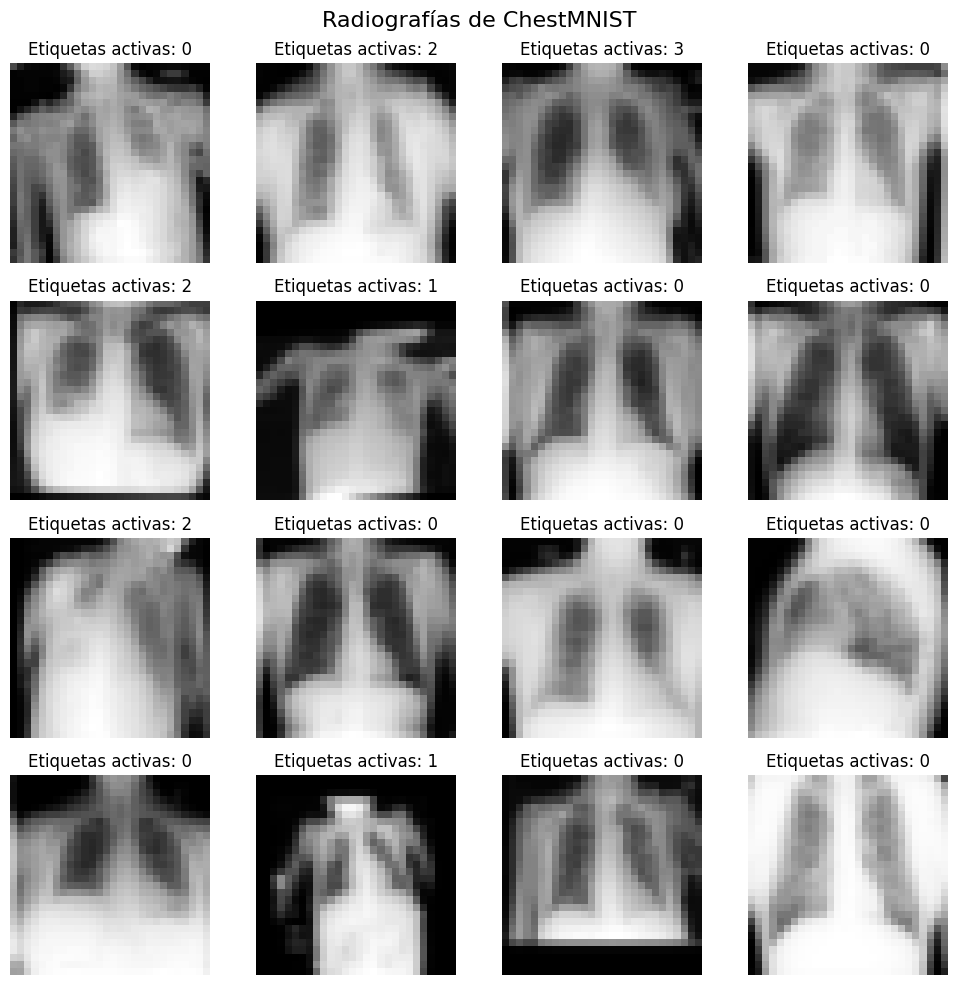

In [6]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
fig.suptitle('Radiografías de ChestMNIST', fontsize=16)

np.random.seed(42)
indices = np.random.choice(len(X_train_full), 16, replace=False)

for ax, indice in zip(axes.flat, indices):
    ax.imshow(X_train_full[indice], cmap='gray')
    ax.set_title(
        f'Etiquetas activas: {int(y_train_cnn[indice].sum())}'
    )
    ax.axis('off')

plt.tight_layout()
plt.show()

## 2.3 Distribución de las etiquetas

Se cuenta la cantidad y el porcentaje de positivos de cada etiqueta en entrenamiento, validación y prueba.

Como el problema es multietiqueta, una imagen puede contribuir al conteo de varias etiquetas. Por tanto, los porcentajes no tienen que sumar 100 %.

También se cuenta cuántas imágenes tienen todas las etiquetas en cero. Esto significa ausencia de positivos registrados entre las 14 etiquetas, no una confirmación de que la imagen sea clínicamente normal.

,Etiqueta,Entrenamiento: positivos,Entrenamiento: %,Validación: positivos,Validación: %,Prueba: positivos,Prueba: %
0,atelectasis,7996,10.19,1119,9.97,2420,10.79
1,cardiomegaly,1950,2.49,240,2.14,582,2.59
2,effusion,9261,11.80,1292,11.52,2754,12.28
3,infiltration,13914,17.73,2018,17.99,3938,17.55
4,mass,3988,5.08,625,5.57,1133,5.05
5,nodule,4375,5.58,613,5.46,1335,5.95
6,pneumonia,978,1.25,133,1.19,242,1.08
7,pneumothorax,3705,4.72,504,4.49,1089,4.85
8,consolidation,3263,4.16,447,3.98,957,4.27
9,edema,1690,2.15,200,1.78,413,1.84


,Partición,Imágenes,Sin etiquetas positivas,Con una etiqueta positiva,Con varias etiquetas positivas
0,Entrenamiento,78468,42405,21602,14461
1,Validación,11219,6079,3112,2028
2,Prueba,22433,11928,6259,4246


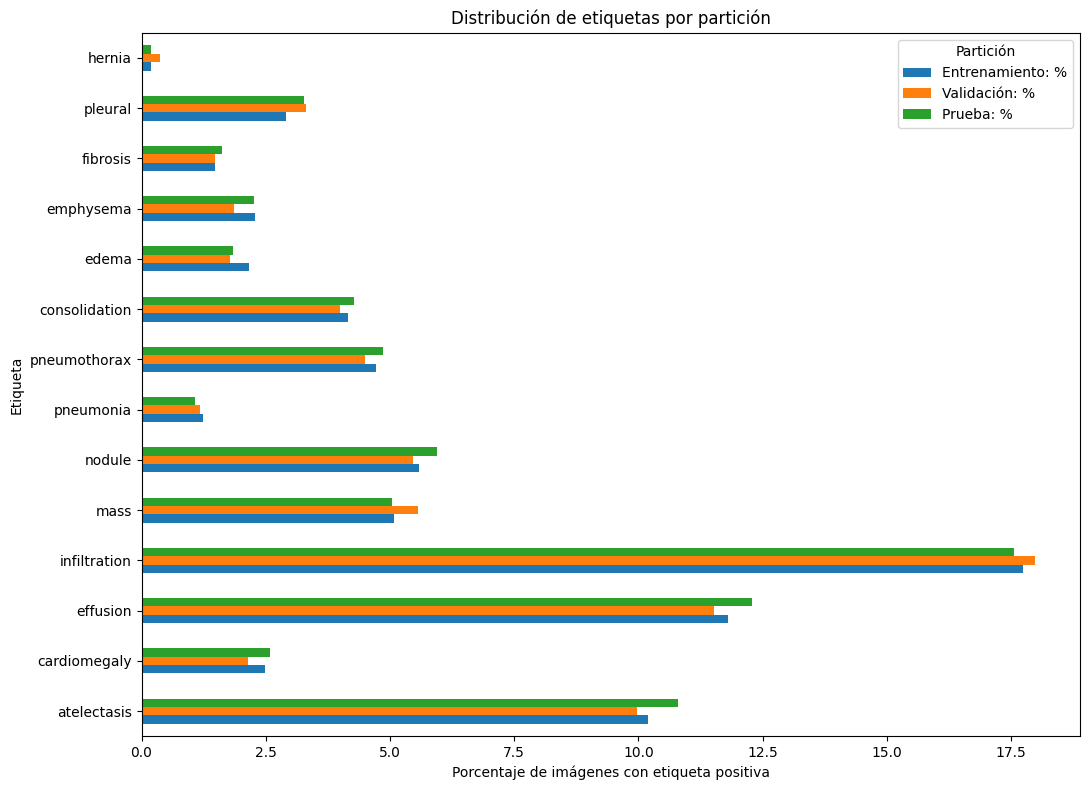

In [23]:
# Usar los datos originales, antes de su preparación
particiones_aed = {
    'Entrenamiento': (X_train_full, train_dataset.labels),
    'Validación': (X_val_full, val_dataset.labels),
    'Prueba': (X_test_full, test_dataset.labels)
}

tabla_distribucion = pd.DataFrame({
    'Etiqueta': nombres_etiquetas
})

resumen_imagenes = []

for nombre, (imagenes, etiquetas) in particiones_aed.items():
    tabla_distribucion[f'{nombre}: positivos'] = (
        etiquetas.sum(axis=0).astype(int)
    )
    tabla_distribucion[f'{nombre}: %'] = (
        etiquetas.mean(axis=0) * 100
    )

    cantidades = etiquetas.sum(axis=1)

    resumen_imagenes.append({
        'Partición': nombre,
        'Imágenes': len(imagenes),
        'Sin etiquetas positivas': int((cantidades == 0).sum()),
        'Con una etiqueta positiva': int((cantidades == 1).sum()),
        'Con varias etiquetas positivas': int((cantidades > 1).sum())
    })

display(tabla_distribucion.round(2))
display(pd.DataFrame(resumen_imagenes))

# Comparar porcentajes, porque las particiones tienen distinto tamaño
columnas_porcentaje = [
    f'{nombre}: %' for nombre in particiones_aed
]

grafico = tabla_distribucion.set_index(
    'Etiqueta'
)[columnas_porcentaje]

ax = grafico.plot.barh(figsize=(11, 8))
ax.set_xlabel('Porcentaje de imágenes con etiqueta positiva')
ax.set_ylabel('Etiqueta')
ax.set_title('Distribución de etiquetas por partición')
ax.legend(title='Partición')
plt.tight_layout()
plt.show()

### Interpretación de la distribución

Infiltration es la etiqueta más frecuente, seguida por effusion y atelectasis. Hernia es la menos frecuente. Los porcentajes son similares entre las tres particiones, aunque presentan algunas diferencias.

En prueba, 11.928 de las 22.433 imágenes no tienen etiquetas positivas registradas; 6.259 tienen una y 4.246 tienen varias.

El predominio de etiquetas negativas explica por qué predecir siempre ausencia alcanza una exactitud binaria elevada. Por eso se complementa esta métrica con AUC, precisión, recall y F1.

## 2.4 Verificación de calidad de los datos

Se comprueba la presencia de valores no finitos, píxeles fuera del intervalo [0, 255], etiquetas distintas de 0 y 1 e imágenes constantes.

También se buscan imágenes con píxeles exactamente iguales dentro de cada partición y entre particiones mediante huellas digitales.

La igualdad de imágenes reducidas a 28 × 28 no permite concluir por sí sola que correspondan al mismo paciente o a la misma imagen original. Estos controles tampoco detectan todas las posibles similitudes.

Esta revisión documenta la calidad de los datos; no modifica las particiones oficiales.

In [24]:
import hashlib

calidad = []
huellas_por_particion = {}

for nombre, (imagenes, etiquetas) in particiones_aed.items():
    pixeles = imagenes.reshape(len(imagenes), -1)

    huellas = [
        hashlib.sha256(imagen.tobytes()).digest()
        for imagen in imagenes
    ]

    huellas_por_particion[nombre] = set(huellas)

    calidad.append({
        'Partición': nombre,
        'Tipo de imagen': str(imagenes.dtype),
        'Píxel mínimo': int(imagenes.min()),
        'Píxel máximo': int(imagenes.max()),
        'Píxeles no finitos': int(
            (~np.isfinite(imagenes)).sum()
        ),
        'Píxeles fuera de rango': int(
            ((imagenes < 0) | (imagenes > 255)).sum()
        ),
        'Etiquetas inválidas': int(
            (~np.isin(etiquetas, [0, 1])).sum()
        ),
        'Imágenes constantes': int(
            (pixeles.min(axis=1) == pixeles.max(axis=1)).sum()
        ),
        'Copias adicionales dentro de la partición': (
            len(huellas) - len(set(huellas))
        )
    })

tabla_calidad = pd.DataFrame(calidad)
display(tabla_calidad)

coincidencias = []

for primera, segunda in [
    ('Entrenamiento', 'Validación'),
    ('Entrenamiento', 'Prueba'),
    ('Validación', 'Prueba')
]:
    coincidencias.append({
        'Primera partición': primera,
        'Segunda partición': segunda,
        'Imágenes distintas con píxeles idénticos': len(
            huellas_por_particion[primera]
            & huellas_por_particion[segunda]
        )
    })

tabla_coincidencias = pd.DataFrame(coincidencias)
display(tabla_coincidencias)

,Partición,Tipo de imagen,Píxel mínimo,Píxel máximo,Píxeles no finitos,Píxeles fuera de rango,Etiquetas inválidas,Imágenes constantes,Copias adicionales dentro de la partición
0,Entrenamiento,uint8,0,253,0,0,0,0,16
1,Validación,uint8,0,253,0,0,0,0,5
2,Prueba,uint8,0,253,0,0,0,0,2


,Primera partición,Segunda partición,Imágenes distintas con píxeles idénticos
0,Entrenamiento,Validación,2
1,Entrenamiento,Prueba,0
2,Validación,Prueba,1


### Interpretación de la calidad

Las imágenes son de tipo uint8 y presentan valores observados entre 0 y 253. No se encontraron píxeles no finitos, valores fuera del intervalo permitido, etiquetas inválidas ni imágenes constantes.

Se encontraron las siguientes copias adicionales con píxeles idénticos dentro de cada partición:

| Partición | Copias adicionales |
|---|---:|
| Entrenamiento | 16 |
| Validación | 5 |
| Prueba | 2 |

Entre particiones se encontraron:

| Comparación | Huellas de imagen compartidas |
|---|---:|
| Entrenamiento y validación | 2 |
| Entrenamiento y prueba | 0 |
| Validación y prueba | 1 |

Las coincidencias entre particiones limitan su independencia. No se encontraron coincidencias exactas entre entrenamiento y prueba, pero este control no descarta imágenes similares ni permite comprobar independencia por paciente.

Se conservaron las particiones oficiales. Las coincidencias se documentan como una limitación de la evaluación.

# FASE 3. Preparación de los datos

Se conservan los píxeles originales como entrada. La normalización se realiza dentro de cada modelo: VGG y ResNet dividen entre 255; MobileNetV2 aplica la transformación x / 127,5 − 1 y redimensiona internamente a 32 × 32, repitiendo el canal gris tres veces.

In [7]:
# Añadir el canal de escala de grises
X_train_cnn = np.expand_dims(X_train_full, axis=-1)
X_val_cnn = np.expand_dims(X_val_full, axis=-1)
X_test_cnn = np.expand_dims(X_test_full, axis=-1)

# Comprobar el formato de entrada
print("Entrenamiento:", X_train_cnn.shape)
print("Validación:", X_val_cnn.shape)
print("Prueba:", X_test_cnn.shape)

# Comprobar GPU antes de construir y entrenar
print("\nGPU disponibles:", tf.config.list_physical_devices('GPU'))

Entrenamiento: (78468, 28, 28, 1)
Validación: (11219, 28, 28, 1)
Prueba: (22433, 28, 28, 1)

GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# FASE 4. Modelado

## 4.1 Arquitecturas propuestas

Se toma como referencia el notebook de BreastMNIST compartido por un compañero y se adaptan sus tres arquitecturas a ChestMNIST:

1. VGG compacta: utiliza bloques de convoluciones para extraer características.
2. ResNet compacta: incorpora conexiones residuales que suman la entrada de un bloque a su salida.
3. MobileNetV2: reutiliza pesos preentrenados en ImageNet. Primero se entrenará su clasificador y después se realizará ajuste fino.

Las tres arquitecturas reciben radiografías y producen 14 probabilidades mediante activación sigmoid, porque una imagen puede presentar varias etiquetas simultáneamente.

VGG y ResNet normalizan los píxeles al intervalo [0, 1]. MobileNetV2 utiliza el intervalo [-1, 1], imágenes de 32 × 32 y tres canales obtenidos repitiendo la escala de grises.

Por ahora se conserva la normalización como tratamiento de entrada. Los filtros utilizados para ecografías en el notebook de referencia requieren una justificación y evaluación específica antes de aplicarlos a nuestras radiografías.

In [10]:
from tensorflow.keras import layers, regularizers

NUM_ETIQUETAS = y_train_cnn.shape[1]
SEMILLAS = [42, 123, 2026]
L2 = 1e-4


# Bloque común: convolución → BatchNormalization → ReLU
def conv_bn_relu(x, filtros, paso=1, activar=True):
    x = layers.Conv2D(
        filtros,
        kernel_size=3,
        strides=paso,
        padding='same',
        use_bias=False,
        kernel_regularizer=regularizers.l2(L2)
    )(x)

    x = layers.BatchNormalization()(x)

    if activar:
        x = layers.Activation('relu')(x)

    return x


# Clasificador multietiqueta común
def clasificador(x, dropout=0.4):
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)

    return layers.Dense(
        NUM_ETIQUETAS,
        activation='sigmoid',
        name='probabilidades'
    )(x)


# CNN 1: VGG compacta
def crear_vgg():
    entrada = tf.keras.Input(shape=(28, 28, 1))
    x = layers.Rescaling(1./255)(entrada)

    # Tamaños espaciales: 28 → 14 → 7 → 3
    for filtros in (16, 32, 64):
        x = conv_bn_relu(x, filtros)
        x = conv_bn_relu(x, filtros)
        x = layers.MaxPooling2D(pool_size=2)(x)
        x = layers.Dropout(0.2)(x)

    x = conv_bn_relu(x, 128)
    x = conv_bn_relu(x, 128, activar=False)
    x = layers.Activation('relu', name='mapa_final')(x)

    salida = clasificador(x)

    return tf.keras.Model(entrada, salida, name='CNN_VGG_compacta')


# Bloque residual para ResNet
def bloque_residual(x, filtros, paso=1):
    atajo = x

    y = conv_bn_relu(x, filtros, paso=paso)
    y = conv_bn_relu(y, filtros, activar=False)

    # Igualar tamaños y canales antes de sumar
    if paso != 1 or x.shape[-1] != filtros:
        atajo = layers.Conv2D(
            filtros,
            kernel_size=1,
            strides=paso,
            padding='same',
            use_bias=False
        )(atajo)

        atajo = layers.BatchNormalization()(atajo)

    return layers.Add()([atajo, y])


# CNN 2: ResNet compacta
def crear_resnet():
    entrada = tf.keras.Input(shape=(28, 28, 1))
    x = layers.Rescaling(1./255)(entrada)

    x = conv_bn_relu(x, 32)
    x = layers.MaxPooling2D(pool_size=2)(x)

    x = bloque_residual(x, 32)
    x = layers.Activation('relu')(x)

    x = bloque_residual(x, 64, paso=2)
    x = layers.Activation('relu')(x)

    x = bloque_residual(x, 128, paso=2)
    x = layers.Activation('relu', name='mapa_final')(x)
    x = layers.Dropout(0.2)(x)

    salida = clasificador(x)

    return tf.keras.Model(entrada, salida, name='CNN_ResNet_compacta')


# CNN 3: MobileNetV2 preentrenada
def crear_mobilenet():
    entrada = tf.keras.Input(shape=(28, 28, 1))

    # Adaptar el tamaño y repetir el canal gris
    x = layers.Resizing(32, 32)(entrada)
    x = layers.Concatenate()([x, x, x])

    # Convertir los píxeles de [0, 255] a [-1, 1]
    x = layers.Rescaling(1./127.5, offset=-1)(x)

    base = tf.keras.applications.MobileNetV2(
        input_shape=(32, 32, 3),
        include_top=False,
        weights='imagenet'
    )

    # Primera fase: entrenar únicamente el clasificador
    base.trainable = False
    x = base(x, training=False)

    x = layers.Activation('linear', name='mapa_final')(x)
    salida = clasificador(x, dropout=0.3)

    return tf.keras.Model(
        entrada, salida, name='CNN_MobileNetV2'
    )


# Guardar las funciones para construir cada arquitectura
ARQUITECTURAS = {
    'VGG compacta': crear_vgg,
    'ResNet compacta': crear_resnet,
    'MobileNetV2': crear_mobilenet
}

print("Arquitecturas definidas:")
for nombre in ARQUITECTURAS:
    print("-", nombre)

print("\nNúmero de etiquetas de salida:", NUM_ETIQUETAS)
print("Semillas para los experimentos:", SEMILLAS)

Arquitecturas definidas:
- VGG compacta
- ResNet compacta
- MobileNetV2

Número de etiquetas de salida: 14
Semillas para los experimentos: [42, 123, 2026]


## 4.2 Verificación de entradas, salidas y parámetros

Se construye cada arquitectura y se comprueba que su salida tenga 14 valores por imagen. También se presenta la cantidad de parámetros totales y entrenables.

Esta verificación todavía no realiza el entrenamiento.

In [11]:
import pandas as pd

verificacion = []

for nombre, construir in ARQUITECTURAS.items():
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    modelo_revision = construir()

    verificacion.append({
        'Arquitectura': nombre,
        'Entrada': str(modelo_revision.input_shape),
        'Salida': str(modelo_revision.output_shape),
        'Parámetros totales': modelo_revision.count_params(),
        'Parámetros entrenables': sum(
            int(np.prod(p.shape))
            for p in modelo_revision.trainable_weights
        )
    })

display(pd.DataFrame(verificacion))

del modelo_revision
tf.keras.backend.clear_session()

/tmp/ipykernel_671/2093857535.py:116: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


,Arquitectura,Entrada,Salida,Parámetros totales,Parámetros entrenables
0,VGG compacta,"(None, 28, 28, 1)","(None, 14)",296478,295518
1,ResNet compacta,"(None, 28, 28, 1)","(None, 14)",309934,308590
2,MobileNetV2,"(None, 28, 28, 1)","(None, 14)",2275918,17934


## 4.3 Configuración del entrenamiento

Cada arquitectura se entrena con las semillas 42, 123 y 2026 para observar cuánto varían sus resultados entre ejecuciones.

VGG y ResNet se entrenan desde cero. MobileNetV2 primero mantiene congelada su base preentrenada y después ajusta sus últimas capas, conservando congeladas las capas BatchNormalization.

Se utiliza binary_crossentropy como pérdida. La métrica de seguimiento es AUC-ROC macro: se calcula una AUC por etiqueta y se promedian las 14.

Se emplea parada temprana para restaurar los pesos de la mejor época de validación y se reduce la tasa de aprendizaje cuando la métrica deja de mejorar.

Como ChestMNIST tiene muchas más imágenes que BreastMNIST, inicialmente se permiten hasta 20 épocas por entrenamiento y hasta 10 adicionales para el ajuste fino.

La arquitectura se selecciona por su AUC macro media en validación. El conjunto de prueba se reserva para la evaluación final.

In [12]:
import time
from pathlib import Path
from sklearn.metrics import roc_auc_score

CONFIG_ENTRENAMIENTO = {
    'epocas': 20,
    'epocas_ajuste_fino': 10,
    'batch_size': 32,
    'paciencia': 5,
    'paciencia_lr': 2,
    'learning_rate': 1e-3,
    'learning_rate_fino': 1e-5
}

CARPETA_MODELOS = Path('resultados_cnn/modelos')
CARPETA_MODELOS.mkdir(parents=True, exist_ok=True)


def entrenar_fase(modelo, learning_rate, epocas):
    # Cada fase utiliza un optimizador nuevo
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss='binary_crossentropy',
        metrics=[
            tf.keras.metrics.AUC(
                name='auc_macro',
                multi_label=True,
                num_labels=NUM_ETIQUETAS
            ),
            tf.keras.metrics.BinaryAccuracy(
                name='binary_accuracy'
            )
        ]
    )

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor='val_auc_macro',
            mode='max',
            patience=CONFIG_ENTRENAMIENTO['paciencia'],
            restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_auc_macro',
            mode='max',
            factor=0.5,
            patience=CONFIG_ENTRENAMIENTO['paciencia_lr'],
            min_lr=1e-7
        )
    ]

    historial = modelo.fit(
        X_train_cnn,
        y_train_cnn,
        validation_data=(X_val_cnn, y_val_cnn),
        epochs=epocas,
        batch_size=CONFIG_ENTRENAMIENTO['batch_size'],
        callbacks=callbacks,
        verbose=2
    )

    return historial.history


def auc_validacion(modelo):
    probabilidades = modelo.predict(
        X_val_cnn,
        batch_size=64,
        verbose=0
    )

    # AUC calculada a partir de todas las probabilidades de validación
    return float(roc_auc_score(
        y_val_cnn,
        probabilidades,
        average='macro'
    ))


print("GPU disponibles:", tf.config.list_physical_devices('GPU'))
print("Configuración preparada.")

GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Configuración preparada.


## 4.4 Entrenamiento con tres semillas

Se registran la arquitectura, la semilla, la cantidad de épocas, el tiempo y la AUC macro de validación.

Cada modelo se guarda al terminar su experimento. En MobileNetV2, si el ajuste fino no mejora la AUC de validación, se recuperan los pesos de la primera fase.

In [13]:
historias = {}
resultados = []

for nombre, construir in ARQUITECTURAS.items():
    for semilla in SEMILLAS:
        print(f"\n{'=' * 60}")
        print(f"Arquitectura: {nombre} | Semilla: {semilla}")
        print(f"{'=' * 60}")

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(semilla)

        modelo = construir()
        inicio = time.perf_counter()

        # Fase inicial
        historia_1 = entrenar_fase(
            modelo,
            CONFIG_ENTRENAMIENTO['learning_rate'],
            CONFIG_ENTRENAMIENTO['epocas']
        )

        historia_2 = None
        fase_elegida = 'Entrenamiento inicial'

        if nombre == 'MobileNetV2':
            auc_fase_1 = auc_validacion(modelo)
            pesos_fase_1 = modelo.get_weights()

            # Localizar la base MobileNetV2
            base = next(
                capa for capa in modelo.layers
                if isinstance(capa, tf.keras.Model)
                and 'mobilenetv2' in capa.name.lower()
            )

            base.trainable = True

            # Ajustar únicamente las últimas 30 capas
            for capa in base.layers:
                capa.trainable = False

            for capa in base.layers[-30:]:
                if not isinstance(capa, layers.BatchNormalization):
                    capa.trainable = True

            print("\nInicio del ajuste fino de MobileNetV2")

            historia_2 = entrenar_fase(
                modelo,
                CONFIG_ENTRENAMIENTO['learning_rate_fino'],
                CONFIG_ENTRENAMIENTO['epocas_ajuste_fino']
            )

            auc_fase_2 = auc_validacion(modelo)

            if auc_fase_2 > auc_fase_1:
                fase_elegida = 'Ajuste fino'
            else:
                modelo.set_weights(pesos_fase_1)
                print("Se recuperan los pesos de la primera fase.")

            del pesos_fase_1

        auc_final = auc_validacion(modelo)
        segundos = time.perf_counter() - inicio

        identificador = nombre.replace(' ', '_')
        ruta = CARPETA_MODELOS / f'{identificador}_{semilla}.keras'
        modelo.save(ruta)

        historias[(nombre, semilla)] = {
            'fase_1': historia_1,
            'fase_2': historia_2,
            'fase_elegida': fase_elegida
        }

        epocas_totales = len(historia_1['loss'])
        if historia_2 is not None:
            epocas_totales += len(historia_2['loss'])

        resultados.append({
            'Arquitectura': nombre,
            'Semilla': semilla,
            'Épocas ejecutadas': epocas_totales,
            'AUC validación': auc_final,
            'Minutos': segundos / 60,
            'Fase elegida': fase_elegida,
            'Ruta modelo': str(ruta)
        })

        # Actualizar el registro después de cada experimento
        registro = pd.DataFrame(resultados)
        registro.to_csv(
            'resultados_cnn/registro_experimentos.csv',
            index=False
        )

        print(f"\nAUC macro de validación: {auc_final:.4f}")
        print(f"Tiempo: {segundos / 60:.1f} minutos")
        print(f"Modelo guardado: {ruta}")

        del modelo

print("\nEntrenamiento de los nueve experimentos terminado.")
display(registro)


Arquitectura: VGG compacta | Semilla: 42
Epoch 1/20
2453/2453 - 44s - 18ms/step - auc_macro: 0.6130 - binary_accuracy: 0.9469 - loss: 0.1973 - val_auc_macro: 0.6667 - val_binary_accuracy: 0.9489 - val_loss: 0.1797 - learning_rate: 0.0010
Epoch 2/20
2453/2453 - 12s - 5ms/step - auc_macro: 0.6469 - binary_accuracy: 0.9486 - loss: 0.1809 - val_auc_macro: 0.6890 - val_binary_accuracy: 0.9483 - val_loss: 0.1772 - learning_rate: 0.0010
Epoch 3/20
2453/2453 - 12s - 5ms/step - auc_macro: 0.6670 - binary_accuracy: 0.9486 - loss: 0.1791 - val_auc_macro: 0.6967 - val_binary_accuracy: 0.9481 - val_loss: 0.1842 - learning_rate: 0.0010
Epoch 4/20
2453/2453 - 11s - 5ms/step - auc_macro: 0.6753 - binary_accuracy: 0.9486 - loss: 0.1777 - val_auc_macro: 0.7019 - val_binary_accuracy: 0.9485 - val_loss: 0.1768 - learning_rate: 0.0010
Epoch 5/20
2453/2453 - 12s - 5ms/step - auc_macro: 0.6842 - binary_accuracy: 0.9486 - loss: 0.1764 - val_auc_macro: 0.6887 - val_binary_accuracy: 0.9488 - val_loss: 0.1785 -

/tmp/ipykernel_671/2093857535.py:116: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


Epoch 1/20
2453/2453 - 42s - 17ms/step - auc_macro: 0.5200 - binary_accuracy: 0.9462 - loss: 0.2822 - val_auc_macro: 0.5416 - val_binary_accuracy: 0.9492 - val_loss: 0.2104 - learning_rate: 0.0010
Epoch 2/20
2453/2453 - 16s - 7ms/step - auc_macro: 0.5495 - binary_accuracy: 0.9486 - loss: 0.1970 - val_auc_macro: 0.5681 - val_binary_accuracy: 0.9492 - val_loss: 0.1838 - learning_rate: 0.0010
Epoch 3/20
2453/2453 - 16s - 6ms/step - auc_macro: 0.5726 - binary_accuracy: 0.9485 - loss: 0.1829 - val_auc_macro: 0.5854 - val_binary_accuracy: 0.9492 - val_loss: 0.1788 - learning_rate: 0.0010
Epoch 4/20
2453/2453 - 16s - 7ms/step - auc_macro: 0.5881 - binary_accuracy: 0.9485 - loss: 0.1802 - val_auc_macro: 0.5947 - val_binary_accuracy: 0.9492 - val_loss: 0.1778 - learning_rate: 0.0010
Epoch 5/20
2453/2453 - 16s - 6ms/step - auc_macro: 0.5936 - binary_accuracy: 0.9485 - loss: 0.1796 - val_auc_macro: 0.5968 - val_binary_accuracy: 0.9492 - val_loss: 0.1775 - learning_rate: 0.0010
Epoch 6/20
2453/245

/tmp/ipykernel_671/2093857535.py:116: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


Epoch 1/20
2453/2453 - 34s - 14ms/step - auc_macro: 0.5195 - binary_accuracy: 0.9468 - loss: 0.2815 - val_auc_macro: 0.5420 - val_binary_accuracy: 0.9492 - val_loss: 0.2101 - learning_rate: 0.0010
Epoch 2/20
2453/2453 - 16s - 7ms/step - auc_macro: 0.5512 - binary_accuracy: 0.9485 - loss: 0.1967 - val_auc_macro: 0.5693 - val_binary_accuracy: 0.9492 - val_loss: 0.1836 - learning_rate: 0.0010
Epoch 3/20
2453/2453 - 16s - 7ms/step - auc_macro: 0.5754 - binary_accuracy: 0.9485 - loss: 0.1828 - val_auc_macro: 0.5867 - val_binary_accuracy: 0.9492 - val_loss: 0.1786 - learning_rate: 0.0010
Epoch 4/20
2453/2453 - 17s - 7ms/step - auc_macro: 0.5891 - binary_accuracy: 0.9485 - loss: 0.1800 - val_auc_macro: 0.5962 - val_binary_accuracy: 0.9492 - val_loss: 0.1777 - learning_rate: 0.0010
Epoch 5/20
2453/2453 - 16s - 7ms/step - auc_macro: 0.5961 - binary_accuracy: 0.9485 - loss: 0.1795 - val_auc_macro: 0.5992 - val_binary_accuracy: 0.9492 - val_loss: 0.1773 - learning_rate: 0.0010
Epoch 6/20
2453/245

/tmp/ipykernel_671/2093857535.py:116: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


Epoch 1/20
2453/2453 - 35s - 14ms/step - auc_macro: 0.5196 - binary_accuracy: 0.9467 - loss: 0.2815 - val_auc_macro: 0.5416 - val_binary_accuracy: 0.9492 - val_loss: 0.2101 - learning_rate: 0.0010
Epoch 2/20
2453/2453 - 17s - 7ms/step - auc_macro: 0.5505 - binary_accuracy: 0.9485 - loss: 0.1967 - val_auc_macro: 0.5687 - val_binary_accuracy: 0.9492 - val_loss: 0.1836 - learning_rate: 0.0010
Epoch 3/20
2453/2453 - 17s - 7ms/step - auc_macro: 0.5739 - binary_accuracy: 0.9486 - loss: 0.1828 - val_auc_macro: 0.5866 - val_binary_accuracy: 0.9492 - val_loss: 0.1786 - learning_rate: 0.0010
Epoch 4/20
2453/2453 - 16s - 7ms/step - auc_macro: 0.5885 - binary_accuracy: 0.9485 - loss: 0.1801 - val_auc_macro: 0.5936 - val_binary_accuracy: 0.9492 - val_loss: 0.1776 - learning_rate: 0.0010
Epoch 5/20
2453/2453 - 17s - 7ms/step - auc_macro: 0.5929 - binary_accuracy: 0.9486 - loss: 0.1795 - val_auc_macro: 0.5963 - val_binary_accuracy: 0.9492 - val_loss: 0.1774 - learning_rate: 0.0010
Epoch 6/20
2453/245

,Arquitectura,Semilla,Épocas ejecutadas,AUC validación,Minutos,Fase elegida,Ruta modelo
0,VGG compacta,42,20,0.765856,4.625660,Entrenamiento inicial,resultados_cnn/modelos/VGG_compacta_42.keras
1,VGG compacta,123,20,0.763854,4.384371,Entrenamiento inicial,resultados_cnn/modelos/VGG_compacta_123.keras
2,VGG compacta,2026,20,0.771024,4.300284,Entrenamiento inicial,resultados_cnn/modelos/VGG_compacta_2026.keras
3,ResNet compacta,42,19,0.747052,4.424519,Entrenamiento inicial,resultados_cnn/modelos/ResNet_compacta_42.keras
4,ResNet compacta,123,20,0.745295,4.353772,Entrenamiento inicial,resultados_cnn/modelos/ResNet_compacta_123.keras
5,ResNet compacta,2026,20,0.755278,5.142719,Entrenamiento inicial,resultados_cnn/modelos/ResNet_compacta_2026.keras
6,MobileNetV2,42,30,0.678550,9.119007,Ajuste fino,resultados_cnn/modelos/MobileNetV2_42.keras
7,MobileNetV2,123,22,0.675051,7.001086,Ajuste fino,resultados_cnn/modelos/MobileNetV2_123.keras
8,MobileNetV2,2026,30,0.672347,9.377817,Ajuste fino,resultados_cnn/modelos/MobileNetV2_2026.keras


## 4.5 Comparación y selección de la arquitectura

Se compara la AUC macro de validación de las tres arquitecturas, calculando su media y desviación estándar entre las tres semillas.

Se selecciona la arquitectura con mayor AUC media. Dentro de ella, se conserva el modelo de la semilla con mayor AUC de validación.

El conjunto de prueba no interviene en esta selección.

,Media,Desviacion,Minimo,Maximo
Arquitectura,,,,
VGG compacta,0.7669,0.0037,0.7639,0.7710
ResNet compacta,0.7492,0.0053,0.7453,0.7553
MobileNetV2,0.6753,0.0031,0.6723,0.6785


Arquitectura seleccionada: VGG compacta
Semilla seleccionada: 2026
AUC de validación: 0.7710


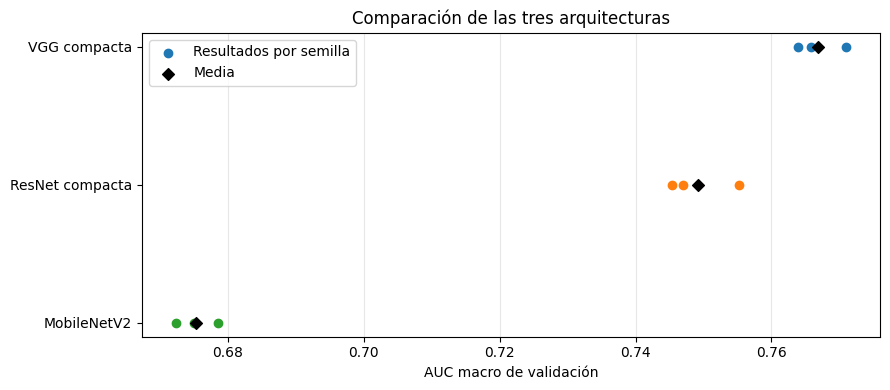

In [14]:
# Comparar las arquitecturas usando únicamente validación
resumen_validacion = (
    registro.groupby('Arquitectura')['AUC validación']
    .agg(
        Media='mean',
        Desviacion='std',
        Minimo='min',
        Maximo='max'
    )
    .sort_values('Media', ascending=False)
)

display(resumen_validacion.round(4))

# Elegir arquitectura y después la mejor semilla dentro de ella
mejor_arquitectura = resumen_validacion.index[0]

fila_elegida = (
    registro[registro['Arquitectura'] == mejor_arquitectura]
    .sort_values('AUC validación', ascending=False)
    .iloc[0]
)

mejor_semilla = int(fila_elegida['Semilla'])

# Recuperar el modelo guardado: no se vuelve a entrenar
cnn_final = tf.keras.models.load_model(
    fila_elegida['Ruta modelo'],
    compile=False
)

historial_final = historias[
    (mejor_arquitectura, mejor_semilla)
]

print("Arquitectura seleccionada:", mejor_arquitectura)
print("Semilla seleccionada:", mejor_semilla)
print(f"AUC de validación: {fila_elegida['AUC validación']:.4f}")

# Mostrar las tres ejecuciones de cada arquitectura
fig, ax = plt.subplots(figsize=(9, 4))

for posicion, nombre in enumerate(resumen_validacion.index):
    valores = registro.loc[
        registro['Arquitectura'] == nombre, 'AUC validación'
    ]

    ax.scatter(
        valores,
        [posicion] * len(valores),
        label='Resultados por semilla' if posicion == 0 else None
    )

    ax.scatter(
        valores.mean(),
        posicion,
        marker='D',
        color='black',
        label='Media' if posicion == 0 else None
    )

ax.set_yticks(
    range(len(resumen_validacion)),
    resumen_validacion.index
)
ax.invert_yaxis()
ax.set_xlabel('AUC macro de validación')
ax.set_title('Comparación de las tres arquitecturas')
ax.grid(axis='x', alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 4.6 Curvas de aprendizaje del modelo seleccionado

Se presentan la pérdida y la AUC macro de entrenamiento y validación de VGG compacta con semilla 2026.

Estas curvas permiten observar cómo evoluciona el aprendizaje. Si el entrenamiento mejora mientras la validación empeora de forma sostenida, puede existir sobreajuste.

La línea vertical señala la época con mayor AUC macro de validación registrada por TensorFlow, cuyos pesos fueron recuperados durante el entrenamiento.

La AUC mostrada durante el entrenamiento es una aproximación mediante umbrales; puede diferir del cálculo posterior con roc_auc_score.

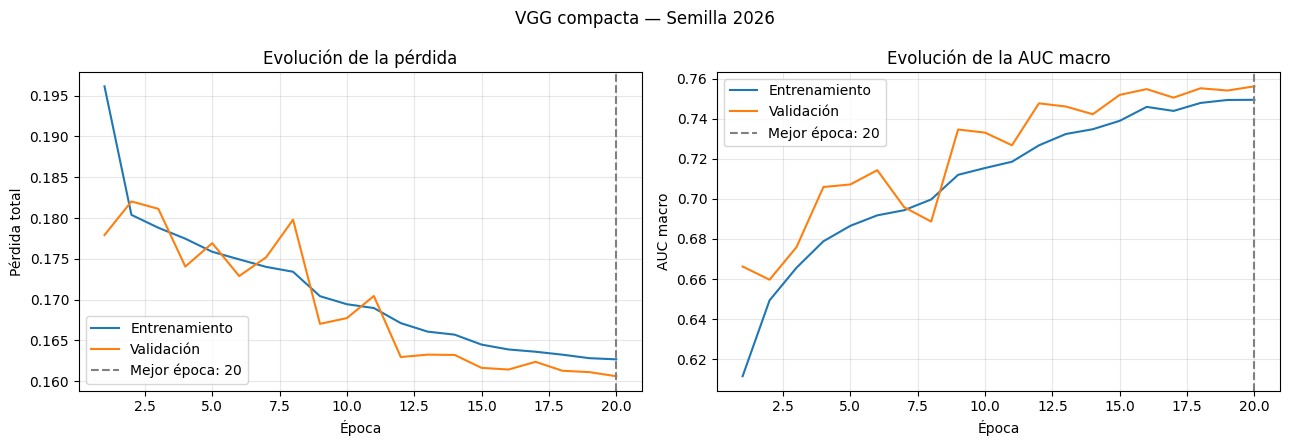

Épocas ejecutadas: 20
Mejor época según AUC de validación: 20
AUC de TensorFlow en esa época: 0.7561


In [15]:
# VGG tiene una única fase de entrenamiento
h = historial_final['fase_1']

epocas = np.arange(1, len(h['loss']) + 1)
mejor_epoca = int(np.argmax(h['val_auc_macro'])) + 1

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Pérdida
axes[0].plot(epocas, h['loss'], label='Entrenamiento')
axes[0].plot(epocas, h['val_loss'], label='Validación')
axes[0].set_title('Evolución de la pérdida')
axes[0].set_ylabel('Pérdida total')

# AUC macro
axes[1].plot(epocas, h['auc_macro'], label='Entrenamiento')
axes[1].plot(epocas, h['val_auc_macro'], label='Validación')
axes[1].set_title('Evolución de la AUC macro')
axes[1].set_ylabel('AUC macro')

for ax in axes:
    ax.axvline(
        mejor_epoca,
        color='gray',
        linestyle='--',
        label=f'Mejor época: {mejor_epoca}'
    )
    ax.set_xlabel('Época')
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle(
    f'{mejor_arquitectura} — Semilla {mejor_semilla}'
)
plt.tight_layout()
plt.show()

print("Épocas ejecutadas:", len(epocas))
print("Mejor época según AUC de validación:", mejor_epoca)
print(
    "AUC de TensorFlow en esa época:",
    round(h['val_auc_macro'][mejor_epoca - 1], 4)
)

# Conservar los valores para consultar cada época
tabla_epocas_cnn = pd.DataFrame(h)
tabla_epocas_cnn.index = pd.RangeIndex(
    1, len(tabla_epocas_cnn) + 1, name='Época'
)

tabla_epocas_cnn.to_csv(
    'resultados_cnn/curvas_modelo_seleccionado.csv'
)

### Interpretación de las curvas

La pérdida de entrenamiento y validación presenta una tendencia descendente, mientras que la AUC macro aumenta en ambos conjuntos.

No se observa un deterioro sostenido de validación mientras mejora el entrenamiento, por lo que estas curvas no muestran evidencia clara de sobreajuste durante las 20 épocas.

La mejor AUC de validación registrada por TensorFlow se alcanzó en la época 20: 0,7561. El cálculo posterior con roc_auc_score obtuvo 0,7710.

Estos resultados describen la capacidad de ordenar los casos positivos y negativos, pero todavía es necesario revisar cuántos positivos detecta el modelo al aplicar un umbral.

# FASE 5. Evaluación

## 5.1 Evaluación inicial en validación con umbral 0,5

Se calculan las probabilidades del modelo seleccionado y se convierten en predicciones binarias: una etiqueta se considera positiva cuando su probabilidad es mayor o igual a 0,5.

Las 14 etiquetas se evalúan de manera independiente. No se utiliza argmax, porque una radiografía puede tener varias etiquetas positivas.

Se reportan precisión, recall y F1 por etiqueta, junto con sus promedios macro y micro. Esta evaluación permitirá revisar el umbral antes de utilizar el conjunto de prueba.

In [16]:
from sklearn.metrics import (
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

# Obtener probabilidades del modelo seleccionado
prob_val_cnn = cnn_final.predict(
    X_val_cnn,
    batch_size=64,
    verbose=0
)

# Aplicar el umbral inicial a cada etiqueta
pred_val_cnn_05 = (prob_val_cnn >= 0.5).astype(int)

print("REPORTE DE VALIDACIÓN — UMBRAL 0,5\n")

print(classification_report(
    y_val_cnn,
    pred_val_cnn_05,
    target_names=nombres_etiquetas,
    digits=4,
    zero_division=0
))

# Resumen global
resumen_val_05 = pd.DataFrame([
    {
        'Promedio': promedio,
        'Precisión': precision_score(
            y_val_cnn, pred_val_cnn_05,
            average=promedio, zero_division=0
        ),
        'Recall': recall_score(
            y_val_cnn, pred_val_cnn_05,
            average=promedio, zero_division=0
        ),
        'F1': f1_score(
            y_val_cnn, pred_val_cnn_05,
            average=promedio, zero_division=0
        )
    }
    for promedio in ['macro', 'micro']
])

display(resumen_val_05.round(4))

positivos_reales = int(y_val_cnn.sum())
positivos_detectados = int(
    ((y_val_cnn == 1) & (pred_val_cnn_05 == 1)).sum()
)

print("Etiquetas positivas reales:", positivos_reales)
print("Etiquetas positivas detectadas:", positivos_detectados)

REPORTE DE VALIDACIÓN — UMBRAL 0,5

               precision    recall  f1-score   support

  atelectasis     0.0000    0.0000    0.0000      1119
 cardiomegaly     0.7500    0.0125    0.0246       240
     effusion     0.5484    0.2237    0.3178      1292
 infiltration     0.0000    0.0000    0.0000      2018
         mass     0.0000    0.0000    0.0000       625
       nodule     0.0000    0.0000    0.0000       613
    pneumonia     0.0000    0.0000    0.0000       133
 pneumothorax     0.0000    0.0000    0.0000       504
consolidation     0.0000    0.0000    0.0000       447
        edema     0.0000    0.0000    0.0000       200
    emphysema     0.0000    0.0000    0.0000       208
     fibrosis     0.0000    0.0000    0.0000       166
      pleural     0.0000    0.0000    0.0000       372
       hernia     0.0000    0.0000    0.0000        41

    micro avg     0.5499    0.0366    0.0686      7978
    macro avg     0.0927    0.0169    0.0245      7978
 weighted avg     0.1114   

,Promedio,Precisión,Recall,F1
0,macro,0.0927,0.0169,0.0245
1,micro,0.5499,0.0366,0.0686


Etiquetas positivas reales: 7978
Etiquetas positivas detectadas: 292


## 5.2 Ajuste de umbrales con validación

Con el umbral inicial de 0,5 se detectaron 292 de las 7.978 etiquetas positivas de validación, con recall micro de 0,0366.

Siguiendo el procedimiento del notebook de referencia, se busca por separado para cada etiqueta el umbral más alto, entre 0,50 y 0,01, que alcance recall de al menos 0,80 en validación.

Si ningún umbral del intervalo alcanza la meta, se conserva 0,01 y se informa que la meta no se logró.

Bajar el umbral permite detectar más positivos, pero también puede aumentar los falsos positivos. Por eso se reportan precisión, F1 y falsas alarmas junto con el recall.

Estos resultados se calculan sobre los mismos datos utilizados para elegir los umbrales y pueden ser optimistas. Los umbrales se fijarán antes de la evaluación final en prueba.

In [17]:
META_RECALL = 0.80

# Buscar desde el umbral más alto hasta el más bajo
umbrales_busqueda = np.round(
    np.arange(0.50, 0.009, -0.01), 2
)

umbrales_cnn = np.full(NUM_ETIQUETAS, 0.5)
filas_umbrales = []

for j, etiqueta in enumerate(nombres_etiquetas):
    reales = y_val_cnn[:, j]
    probabilidades = prob_val_cnn[:, j]
    positivos = int(reales.sum())

    # Si no hubiera positivos, no se podría ajustar por recall
    if positivos == 0:
        umbral = 0.5
        cumple = False
    else:
        umbral = float(umbrales_busqueda[-1])
        cumple = False

        for candidato in umbrales_busqueda:
            pred = probabilidades >= candidato
            vp = int(((reales == 1) & pred).sum())

            if vp / positivos >= META_RECALL:
                umbral = float(candidato)
                cumple = True
                break

    umbrales_cnn[j] = umbral
    pred = (probabilidades >= umbral).astype(int)

    filas_umbrales.append({
        'Etiqueta': etiqueta,
        'Positivos reales': positivos,
        'Umbral': umbral,
        'Precisión': precision_score(
            reales, pred, zero_division=0
        ),
        'Recall': recall_score(
            reales, pred, zero_division=0
        ),
        'F1': f1_score(
            reales, pred, zero_division=0
        ),
        'Falsos positivos': int(
            ((reales == 0) & (pred == 1)).sum()
        ),
        'Meta alcanzada': (
            'Sin positivos' if positivos == 0
            else 'Sí' if cumple else 'No'
        )
    })

tabla_umbrales = pd.DataFrame(filas_umbrales)
display(tabla_umbrales.round(4))

# Aplicar un umbral diferente a cada columna
pred_val_cnn_aj = (
    prob_val_cnn >= umbrales_cnn
).astype(int)

print("\nREPORTE CON UMBRALES AJUSTADOS\n")

print(classification_report(
    y_val_cnn,
    pred_val_cnn_aj,
    target_names=nombres_etiquetas,
    digits=4,
    zero_division=0
))

# Guardar los umbrales elegidos únicamente con validación
tabla_umbrales.to_csv(
    'resultados_cnn/umbrales_validacion.csv',
    index=False
)

,Etiqueta,Positivos reales,Umbral,Precisión,Recall,F1,Falsos positivos,Meta alcanzada
0,atelectasis,1119,0.08,0.1722,0.8043,0.2837,4326,Sí
1,cardiomegaly,240,0.01,0.0601,0.8167,0.1120,3064,Sí
2,effusion,1292,0.12,0.2826,0.8096,0.4190,2655,Sí
3,infiltration,2018,0.11,0.2211,0.8538,0.3512,6070,Sí
4,mass,625,0.04,0.1069,0.8240,0.1893,4301,Sí
5,nodule,613,0.03,0.0607,0.9266,0.1140,8786,Sí
6,pneumonia,133,0.01,0.0223,0.7293,0.0433,4249,No
7,pneumothorax,504,0.03,0.0901,0.8373,0.1627,4263,Sí
8,consolidation,447,0.03,0.0807,0.8434,0.1472,4297,Sí
9,edema,200,0.02,0.0708,0.8400,0.1306,2205,Sí



REPORTE CON UMBRALES AJUSTADOS

               precision    recall  f1-score   support

  atelectasis     0.1722    0.8043    0.2837      1119
 cardiomegaly     0.0601    0.8167    0.1120       240
     effusion     0.2826    0.8096    0.4190      1292
 infiltration     0.2211    0.8538    0.3512      2018
         mass     0.1069    0.8240    0.1893       625
       nodule     0.0607    0.9266    0.1140       613
    pneumonia     0.0223    0.7293    0.0433       133
 pneumothorax     0.0901    0.8373    0.1627       504
consolidation     0.0807    0.8434    0.1472       447
        edema     0.0708    0.8400    0.1306       200
    emphysema     0.0285    0.8654    0.0552       208
     fibrosis     0.0229    0.7229    0.0443       166
      pleural     0.0429    0.9140    0.0820       372
       hernia     0.0411    0.0732    0.0526        41

    micro avg     0.0954    0.8342    0.1712      7978
    macro avg     0.0931    0.7757    0.1562      7978
 weighted avg     0.1565    0.

### Interpretación del ajuste en validación

Los umbrales ajustados aumentaron el recall micro de 0,0366 a 0,8342 y el F1 micro de 0,0686 a 0,1712. Sin embargo, la precisión micro descendió de 0,5499 a 0,0954.

El modelo detecta más etiquetas positivas a costa de generar numerosas falsas alarmas. Por tanto, alcanzar un recall elevado no implica un buen desempeño global.

Once de las catorce etiquetas alcanzaron la meta exploratoria de recall en validación. Pneumonia, fibrosis y hernia no la alcanzaron con los umbrales evaluados.

Se conservan los umbrales elegidos para comprobar su comportamiento en prueba, sin ajustarlos con ese conjunto.

## 5.3 Evaluación final en el conjunto de prueba

Se generan las probabilidades del modelo seleccionado sobre las imágenes de prueba.

Se comparan tres alternativas:
- Línea base: predecir ausencia en las 14 etiquetas.
- CNN con umbral 0,5.
- CNN con los umbrales fijados en validación.

Se reportan precisión, recall, F1, exactitud binaria y coincidencia exacta. La coincidencia exacta exige acertar simultáneamente las 14 etiquetas de una imagen.

La AUC se calcula sobre las probabilidades y no cambia al modificar el umbral.

In [18]:
from sklearn.metrics import accuracy_score

# Generar las probabilidades de prueba y reutilizarlas
prob_test_cnn = cnn_final.predict(
    X_test_cnn,
    batch_size=64,
    verbose=0
)

pred_test_cnn_05 = (prob_test_cnn >= 0.5).astype(int)
pred_test_cnn_aj = (
    prob_test_cnn >= umbrales_cnn
).astype(int)

pred_test_base = np.zeros_like(y_test_cnn)

auc_test_cnn = roc_auc_score(
    y_test_cnn,
    prob_test_cnn,
    average='macro'
)


def resumir_prueba(nombre, predicciones, auc):
    return {
        'Alternativa': nombre,
        'AUC macro': auc,
        'Precisión micro': precision_score(
            y_test_cnn, predicciones,
            average='micro', zero_division=0
        ),
        'Recall micro': recall_score(
            y_test_cnn, predicciones,
            average='micro', zero_division=0
        ),
        'F1 micro': f1_score(
            y_test_cnn, predicciones,
            average='micro', zero_division=0
        ),
        'F1 macro': f1_score(
            y_test_cnn, predicciones,
            average='macro', zero_division=0
        ),
        'Exactitud binaria': float(
            (y_test_cnn == predicciones).mean()
        ),
        'Coincidencia exacta': accuracy_score(
            y_test_cnn, predicciones
        ),
        'Verdaderos positivos': int(
            ((y_test_cnn == 1) & (predicciones == 1)).sum()
        ),
        'Falsos positivos': int(
            ((y_test_cnn == 0) & (predicciones == 1)).sum()
        ),
        'Falsos negativos': int(
            ((y_test_cnn == 1) & (predicciones == 0)).sum()
        )
    }


tabla_test_cnn = pd.DataFrame([
    resumir_prueba('Siempre ausencia', pred_test_base, 0.5),
    resumir_prueba('CNN — umbral 0,5', pred_test_cnn_05, auc_test_cnn),
    resumir_prueba(
        'CNN — umbrales ajustados',
        pred_test_cnn_aj,
        auc_test_cnn
    )
])

display(tabla_test_cnn.round(4))

print("\nREPORTE DE PRUEBA — UMBRALES AJUSTADOS\n")
print(classification_report(
    y_test_cnn,
    pred_test_cnn_aj,
    target_names=nombres_etiquetas,
    digits=4,
    zero_division=0
))

# Guardar resultados para el análisis y la comparación con RNA
tabla_test_cnn.to_csv(
    'resultados_cnn/evaluacion_test.csv',
    index=False
)

np.savez_compressed(
    'resultados_cnn/predicciones_test_CNN.npz',
    y_real=y_test_cnn,
    probabilidades=prob_test_cnn,
    pred_05=pred_test_cnn_05,
    pred_ajustadas=pred_test_cnn_aj,
    umbrales=umbrales_cnn,
    etiquetas=np.asarray(nombres_etiquetas)
)

,Alternativa,AUC macro,Precisión micro,Recall micro,F1 micro,F1 macro,Exactitud binaria,Coincidencia exacta,Verdaderos positivos,Falsos positivos,Falsos negativos
0,Siempre ausencia,0.5000,0.0000,0.0000,0.0000,0.0000,0.9474,0.5317,0,0,16510
1,"CNN — umbral 0,5",0.7654,0.5795,0.0371,0.0697,0.0251,0.9480,0.5331,612,444,15898
2,CNN — umbrales ajustados,0.7654,0.0975,0.8390,0.1747,0.1563,0.5832,0.0500,13852,128237,2658



REPORTE DE PRUEBA — UMBRALES AJUSTADOS

               precision    recall  f1-score   support

  atelectasis     0.1884    0.8223    0.3065      2420
 cardiomegaly     0.0726    0.8746    0.1341       582
     effusion     0.2941    0.8043    0.4307      2754
 infiltration     0.2141    0.8685    0.3436      3938
         mass     0.0911    0.7732    0.1631      1133
       nodule     0.0665    0.9258    0.1241      1335
    pneumonia     0.0185    0.6942    0.0360       242
 pneumothorax     0.0954    0.8494    0.1716      1089
consolidation     0.0838    0.8380    0.1523       957
        edema     0.0638    0.7821    0.1180       413
    emphysema     0.0351    0.8821    0.0676       509
     fibrosis     0.0267    0.7845    0.0517       362
      pleural     0.0414    0.8910    0.0790       734
       hernia     0.0063    0.0238    0.0099        42

    micro avg     0.0975    0.8390    0.1747     16510
    macro avg     0.0927    0.7724    0.1563     16510
 weighted avg     0.15

### Interpretación de la evaluación final

La CNN seleccionada obtuvo una AUC macro de 0,7654 en prueba, frente a 0,7710 en validación.

Con umbral 0,5 detectó 612 de las 16.510 etiquetas positivas. Su exactitud binaria fue 0,9480, muy cercana a la línea base que siempre predice ausencia (0,9474). Esto demuestra por qué una exactitud elevada no implica una buena detección de positivos.

Los umbrales ajustados aumentaron la detección a 13.852 etiquetas positivas, con recall micro de 0,8390. Sin embargo, produjeron 128.237 falsos positivos y una precisión micro de 0,0975.

Los conteos corresponden a decisiones por etiqueta, no a pacientes ni a radiografías diferentes.

El ajuste aumentó el F1 micro, pero el desempeño continúa siendo limitado. El recall micro superior a 0,80 tampoco significa que todas las etiquetas alcancen esa sensibilidad: por ejemplo, hernia presentó recall de 0,0238.

## 5.4 Matrices de confusión por etiqueta

Se construye una matriz de confusión para cada una de las 14 etiquetas utilizando los umbrales fijados en validación.

Las filas representan las etiquetas reales y las columnas las predicciones:

| | Predicción 0 | Predicción 1 |
|---|---|---|
| Real 0 | Verdaderos negativos | Falsos positivos |
| Real 1 | Falsos negativos | Verdaderos positivos |

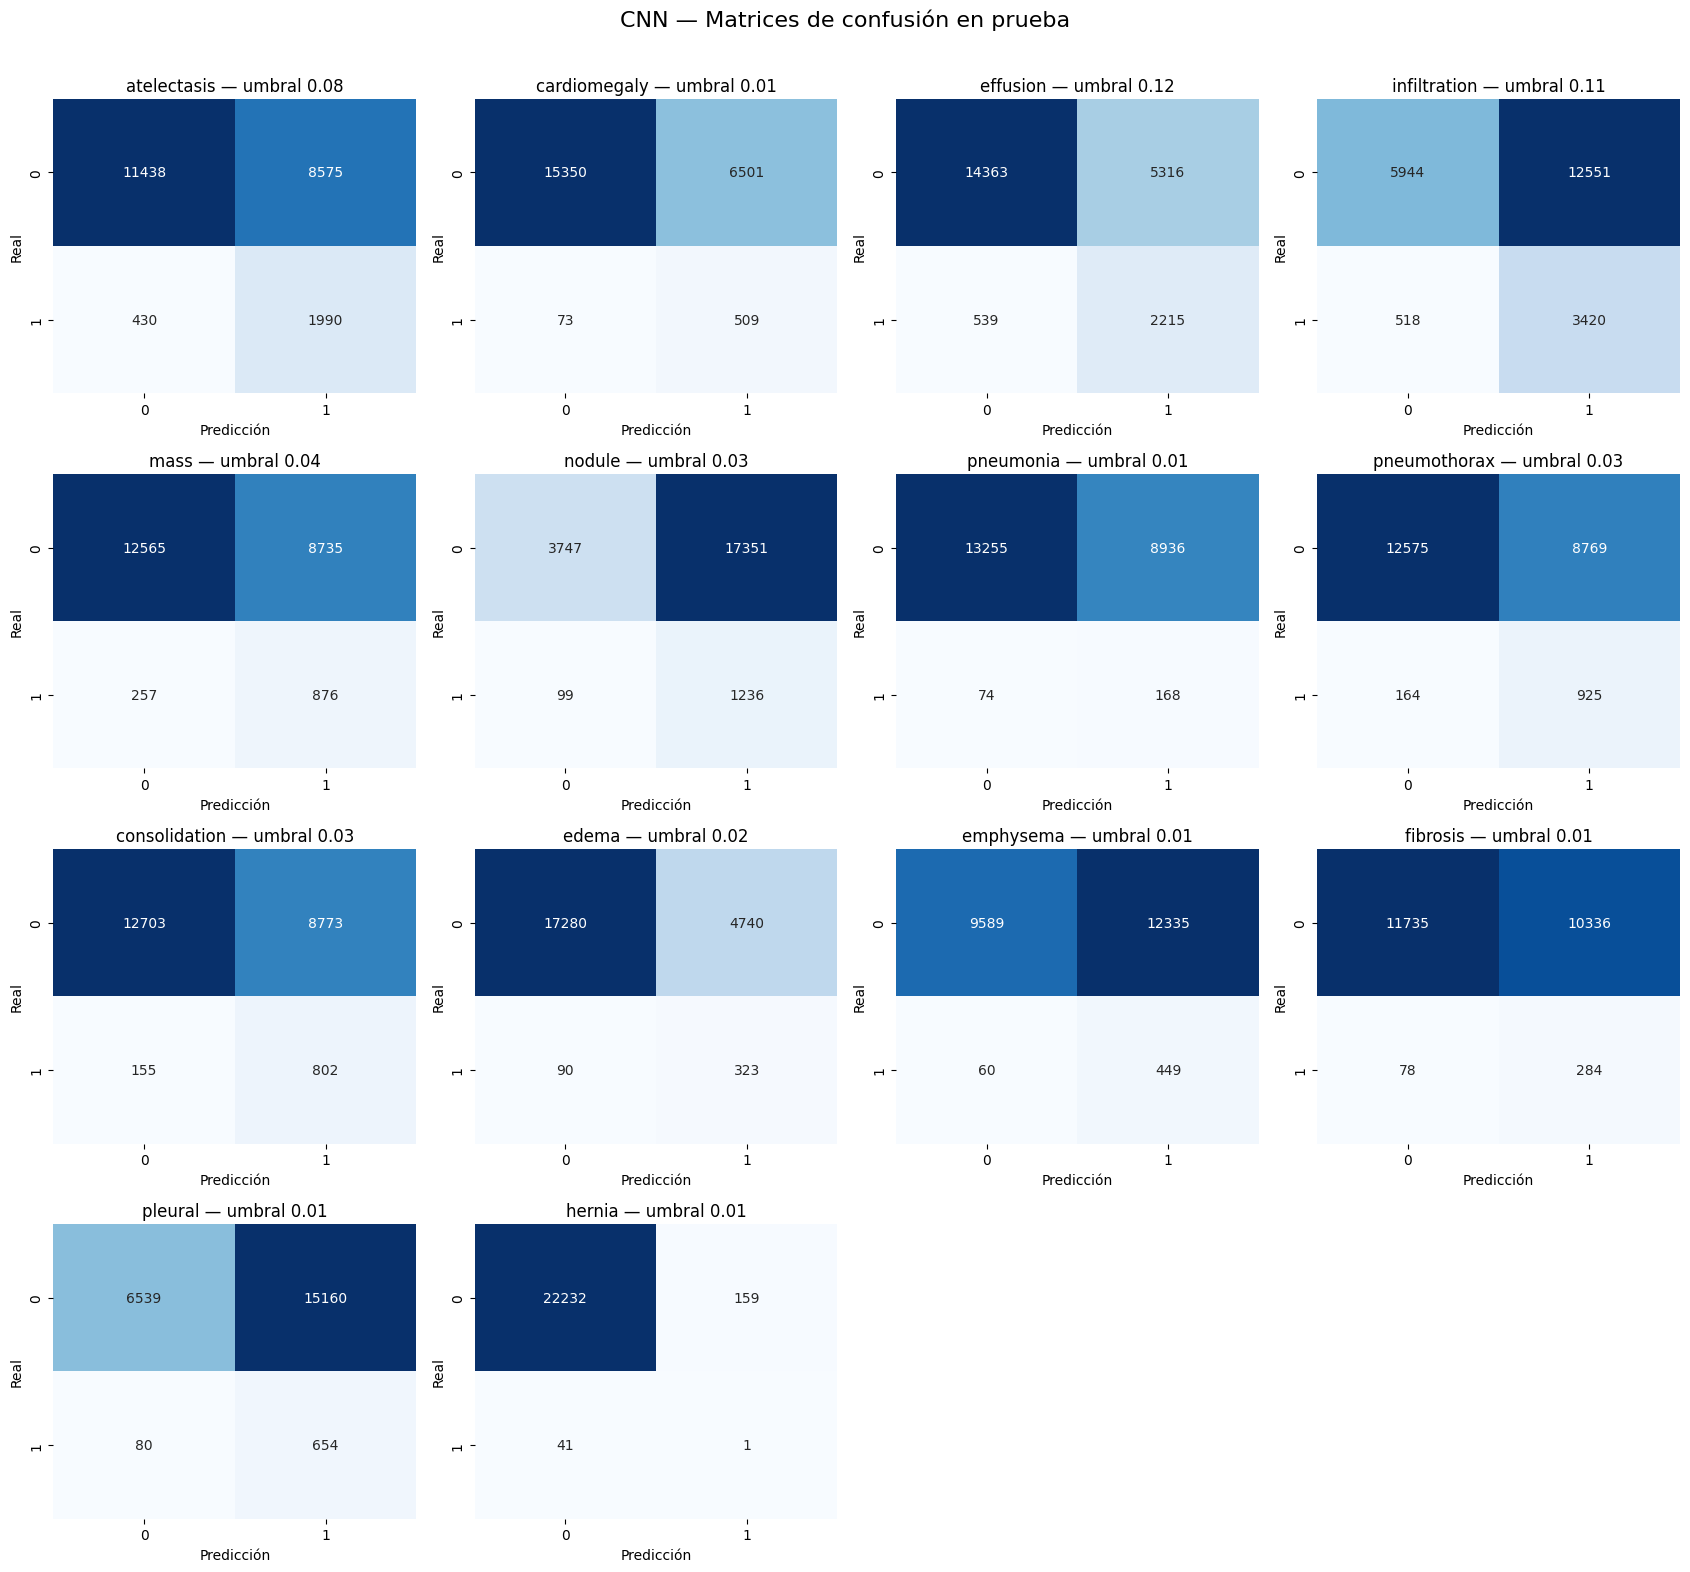

,Etiqueta,Umbral,VN,FP,FN,VP
0,atelectasis,0.08,11438,8575,430,1990
1,cardiomegaly,0.01,15350,6501,73,509
2,effusion,0.12,14363,5316,539,2215
3,infiltration,0.11,5944,12551,518,3420
4,mass,0.04,12565,8735,257,876
5,nodule,0.03,3747,17351,99,1236
6,pneumonia,0.01,13255,8936,74,168
7,pneumothorax,0.03,12575,8769,164,925
8,consolidation,0.03,12703,8773,155,802
9,edema,0.02,17280,4740,90,323


In [19]:
import seaborn as sns
from sklearn.metrics import multilabel_confusion_matrix

matrices_cnn = multilabel_confusion_matrix(
    y_test_cnn,
    pred_test_cnn_aj
)

fig, axes = plt.subplots(4, 4, figsize=(17, 16))
filas_matrices = []

for j, etiqueta in enumerate(nombres_etiquetas):
    ax = axes.flat[j]
    matriz = matrices_cnn[j]

    sns.heatmap(
        matriz,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        xticklabels=['0', '1'],
        yticklabels=['0', '1'],
        ax=ax
    )

    ax.set_title(
        f'{etiqueta} — umbral {umbrales_cnn[j]:.2f}'
    )
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Real')

    vn, fp, fn, vp = matriz.ravel()

    filas_matrices.append({
        'Etiqueta': etiqueta,
        'Umbral': umbrales_cnn[j],
        'VN': int(vn),
        'FP': int(fp),
        'FN': int(fn),
        'VP': int(vp)
    })

# Ocultar los dos espacios sobrantes
for ax in axes.flat[NUM_ETIQUETAS:]:
    ax.axis('off')

fig.suptitle(
    'CNN — Matrices de confusión en prueba',
    fontsize=16
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

tabla_matrices_cnn = pd.DataFrame(filas_matrices)
display(tabla_matrices_cnn)

tabla_matrices_cnn.to_csv(
    'resultados_cnn/matrices_confusion_test.csv',
    index=False
)

### Interpretación de las matrices de confusión

Los umbrales ajustados permiten detectar una proporción elevada de positivos en varias etiquetas, pero también generan numerosos falsos positivos.

Por ejemplo, effusion presenta 2.215 verdaderos positivos y 5.316 falsos positivos. Nodule detecta 1.236 positivos, pero produce 17.351 falsas alarmas.

El comportamiento no es uniforme: hernia identifica solamente uno de los 42 positivos del conjunto de prueba.

Estos resultados muestran que el recall global debe complementarse con precisión y resultados por etiqueta. El modelo no presenta un desempeño suficiente para utilizar sus predicciones como decisiones diagnósticas.

## 5.5 Curvas ROC y AUC por etiqueta

La curva ROC representa la relación entre la proporción de positivos detectados y la proporción de falsas alarmas al variar el umbral.

Se calcula una curva y su AUC para cada etiqueta. La diagonal representa una puntuación sin capacidad discriminativa, con AUC de 0,5.

Estas curvas utilizan las probabilidades de prueba ya calculadas. Se presentan para describir el desempeño final, sin modificar el modelo ni los umbrales.

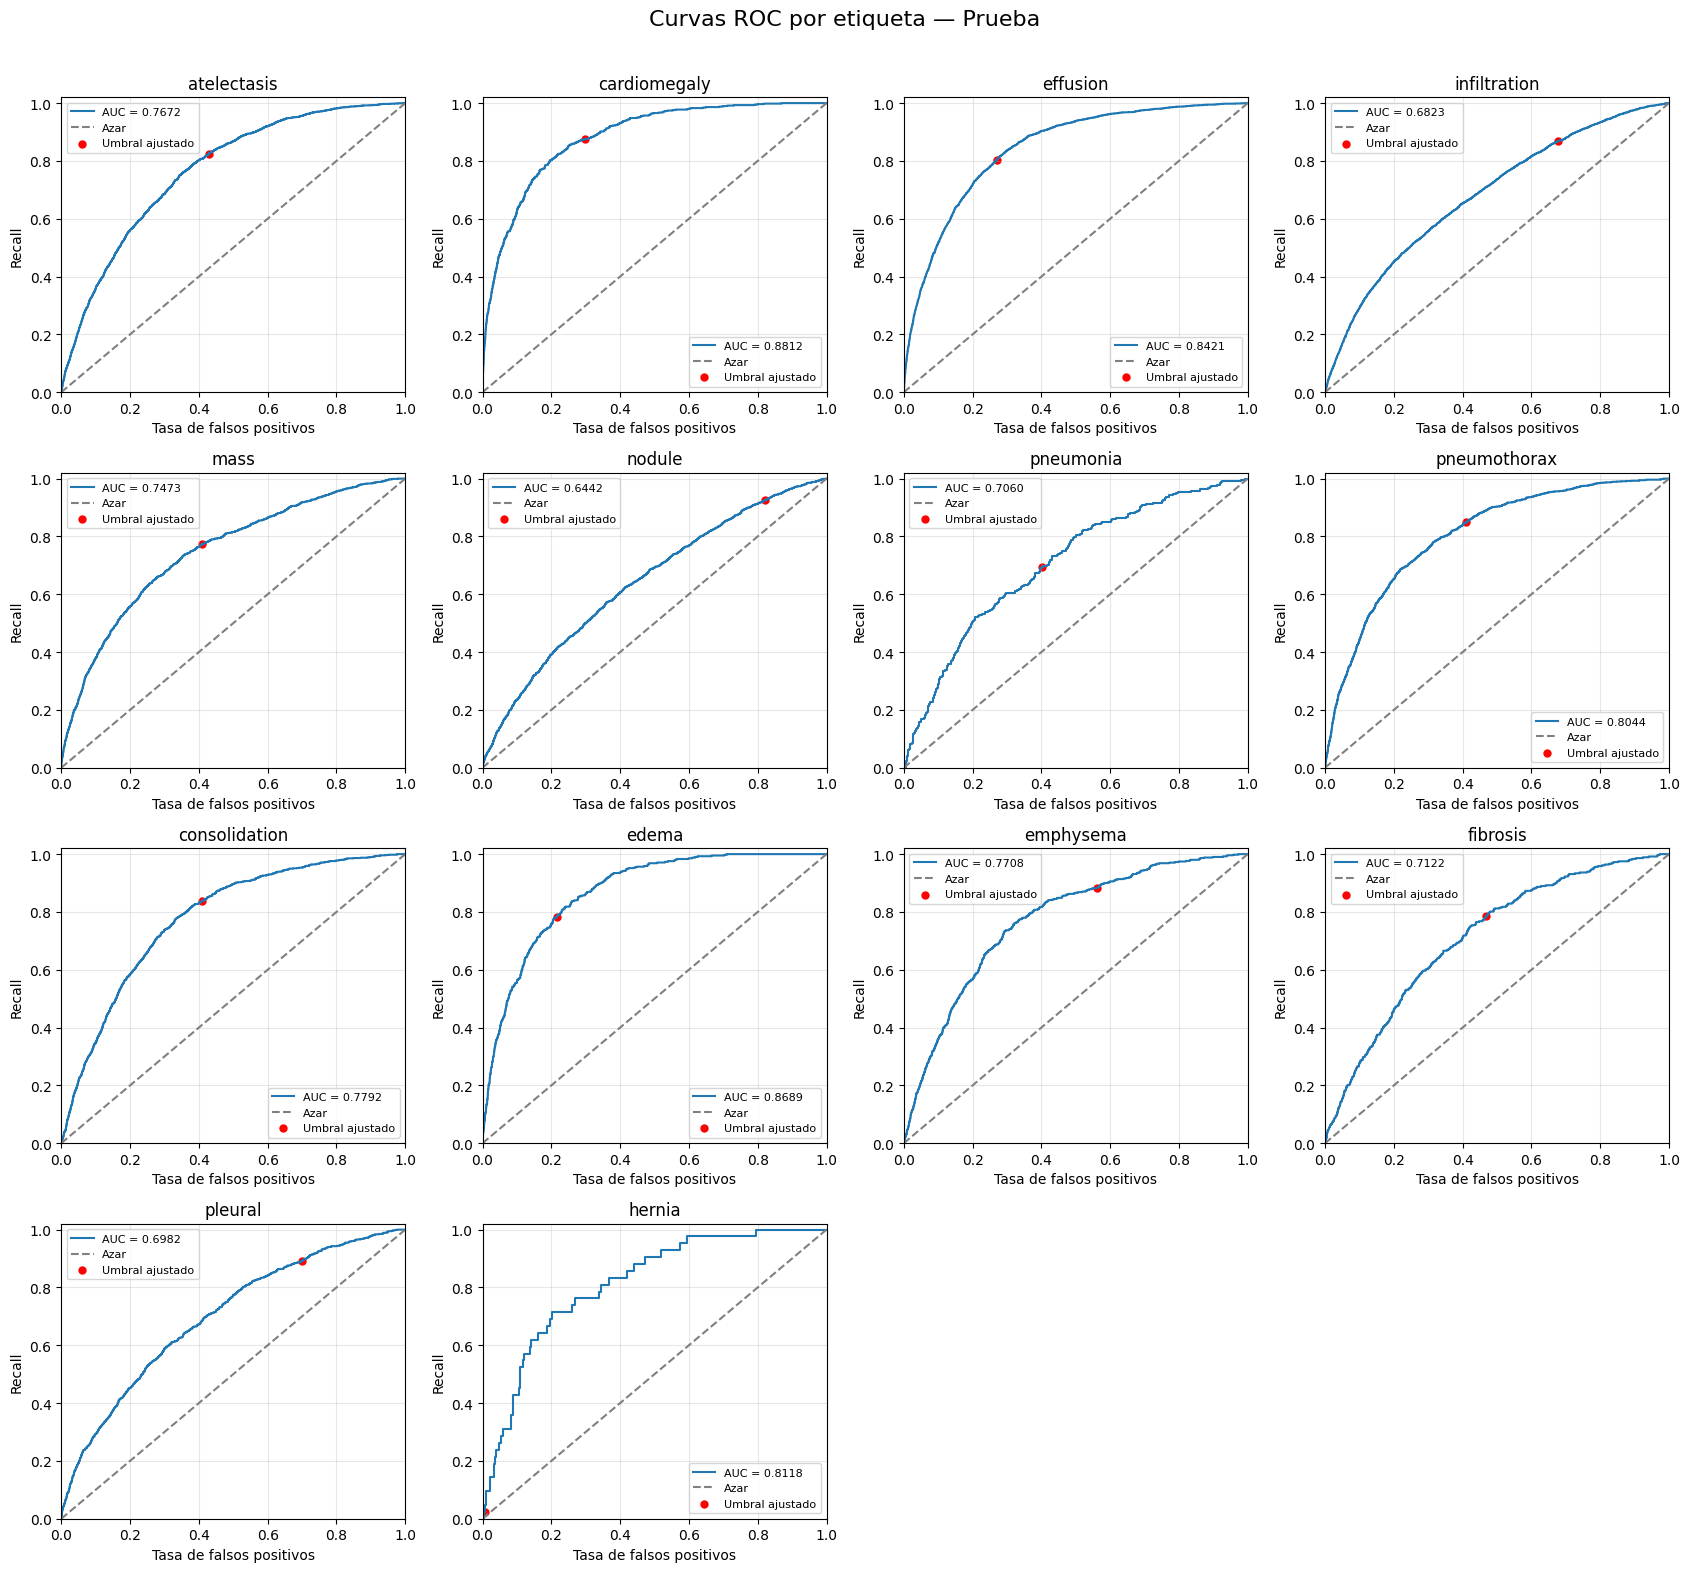

,Etiqueta,AUC
1,cardiomegaly,0.8812
9,edema,0.8689
2,effusion,0.8421
13,hernia,0.8118
7,pneumothorax,0.8044
8,consolidation,0.7792
10,emphysema,0.7708
0,atelectasis,0.7672
4,mass,0.7473
11,fibrosis,0.7122


In [20]:
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(4, 4, figsize=(17, 16))
filas_auc = []

for j, etiqueta in enumerate(nombres_etiquetas):
    ax = axes.flat[j]
    reales = y_test_cnn[:, j]
    probabilidades = prob_test_cnn[:, j]

    # La AUC requiere positivos y negativos
    if len(np.unique(reales)) < 2:
        ax.set_title(f'{etiqueta}: AUC no definida')
        filas_auc.append({
            'Etiqueta': etiqueta,
            'AUC': np.nan
        })
        continue

    fpr, tpr, _ = roc_curve(reales, probabilidades)
    auc_etiqueta = roc_auc_score(reales, probabilidades)

    ax.plot(
        fpr, tpr,
        label=f'AUC = {auc_etiqueta:.4f}'
    )
    ax.plot(
        [0, 1], [0, 1],
        linestyle='--',
        color='gray',
        label='Azar'
    )

    # Punto correspondiente al umbral fijado en validación
    matriz = matrices_cnn[j]
    vn, fp, fn, vp = matriz.ravel()

    ax.scatter(
        fp / (fp + vn),
        vp / (vp + fn),
        color='red',
        s=25,
        label='Umbral ajustado'
    )

    ax.set_title(etiqueta)
    ax.set_xlabel('Tasa de falsos positivos')
    ax.set_ylabel('Recall')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

    filas_auc.append({
        'Etiqueta': etiqueta,
        'AUC': auc_etiqueta
    })

for ax in axes.flat[NUM_ETIQUETAS:]:
    ax.axis('off')

fig.suptitle('Curvas ROC por etiqueta — Prueba', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

tabla_auc_cnn = pd.DataFrame(filas_auc)
display(tabla_auc_cnn.sort_values('AUC', ascending=False).round(4))

tabla_auc_cnn.to_csv(
    'resultados_cnn/auc_por_etiqueta.csv',
    index=False
)

### Interpretación de la AUC por etiqueta

Las mayores AUC de prueba fueron cardiomegaly (0,8812), edema (0,8689) y effusion (0,8421). Las menores fueron nodule (0,6442), infiltration (0,6823) y pleural (0,6982).

El desempeño depende de la etiqueta y no queda completamente representado por la AUC macro de 0,7654.

Hernia obtuvo una AUC de 0,8118, pero con el umbral fijado en validación detectó solamente uno de sus 42 positivos. Esto demuestra que una AUC elevada no garantiza un recall elevado en un umbral específico.

La búsqueda de umbrales estuvo limitada al intervalo [0,01, 0,50]. No se exploraron valores inferiores a 0,01, lo que constituye una limitación del procedimiento.

# FASE 6. Despliegue académico y conclusiones

## 6.1 Conclusiones

Se compararon VGG compacta, ResNet compacta y MobileNetV2 con tres semillas por arquitectura. VGG compacta obtuvo la mayor AUC macro media de validación: 0,7669, frente a 0,7492 de ResNet y 0,6753 de MobileNetV2.

Dentro de VGG se seleccionó la semilla 2026, con AUC de validación de 0,7710. En prueba alcanzó una AUC macro de 0,7654.

Con umbral 0,5, el modelo detectó 612 de las 16.510 etiquetas positivas de prueba. Su exactitud binaria fue cercana a la línea base que siempre predice ausencia, por lo que esta métrica aislada resultó insuficiente.

Con los umbrales ajustados en validación se detectaron 13.852 positivos y el recall micro aumentó a 0,8390. Sin embargo, se produjeron 128.237 falsos positivos, con precisión micro de 0,0975 y F1 micro de 0,1747.

La CNN aprendió patrones discriminativos, pero las decisiones obtenidas presentan un intercambio importante entre detección y falsas alarmas. Los resultados no permiten proponer su uso diagnóstico.

## 6.2 Limitaciones

- Imágenes de baja resolución: 28 × 28 píxeles.
- Frecuencias diferentes entre las etiquetas.
- Evaluación limitada a las particiones de ChestMNIST, sin validación externa.
- Entrenamiento limitado a las épocas configuradas.
- Selección de arquitectura, semilla y umbrales sobre el mismo conjunto de validación.
- Búsqueda de umbrales limitada al intervalo [0,01, 0,50].
- AUC de seguimiento aproximada mediante umbrales de TensorFlow.
- No se ha demostrado qué factor explica las diferencias entre las arquitecturas.
- Se encontraron imágenes con píxeles idénticos dentro de las particiones, dos huellas compartidas entre entrenamiento y validación y una entre validación y prueba. El control de igualdad exacta no permite descartar otras dependencias entre imágenes.

## 6.3 Trabajo futuro

Como experimentos futuros se propone estudiar estrategias de manejo del desbalance multietiqueta, evaluar mayor resolución y comparar reglas de selección de umbrales mediante validación.

La comparación con la RNA basada en HOG debe utilizar las mismas imágenes de prueba y métricas equivalentes.

## 6.4 Guardado del modelo

Se conserva el modelo seleccionado junto con el orden de las etiquetas, sus umbrales y la configuración del experimento.

El guardado permite reutilizar las predicciones en una demostración académica sin repetir el entrenamiento. No representa un despliegue clínico.

In [27]:
ruta_final = CARPETA_MODELOS / 'ChestMNIST_CNN_final.keras'
cnn_final.save(ruta_final)

metadatos = {
    'dataset': 'ChestMNIST',
    'arquitectura': mejor_arquitectura,
    'semilla': int(mejor_semilla),
    'entrada': [28, 28, 1],
    'rango_entrada': [0, 255],
    'normalizacion': 'Incluida dentro del modelo',
    'etiquetas': list(nombres_etiquetas),
    'umbrales': umbrales_cnn.tolist(),
    'regla_decision': 'probabilidad >= umbral por etiqueta',
    'meta_recall_validacion': float(META_RECALL),
    'auc_validacion': float(fila_elegida['AUC validación']),
    'auc_test': float(auc_test_cnn),
    'configuracion_entrenamiento': CONFIG_ENTRENAMIENTO,
    'version_tensorflow': tf.__version__
}

with open(
    'resultados_cnn/metadatos_modelo_final.json',
    'w',
    encoding='utf-8'
) as archivo:
    json.dump(metadatos, archivo, ensure_ascii=False, indent=2)

modelo_recuperado = tf.keras.models.load_model(
    ruta_final,
    compile=False
)

prob_comprobacion = modelo_recuperado.predict(
    X_test_cnn[:8],
    verbose=0
)

np.testing.assert_allclose(
    prob_comprobacion,
    prob_test_cnn[:8],
    rtol=1e-4,
    atol=1e-5
)

print("Modelo guardado y recuperado correctamente.")

Modelo guardado y recuperado correctamente.


## 6.5 Demostración de predicción sobre una radiografía

Se utiliza el modelo guardado para calcular las 14 probabilidades de una imagen y aplicar los umbrales elegidos en validación.

La tabla muestra las etiquetas registradas en el dataset, las probabilidades del modelo y sus predicciones. Permite observar aciertos, falsos positivos y falsos negativos.

La imagen utilizada pertenece al conjunto de prueba; esta demostración no constituye una validación con imágenes externas ni un diagnóstico médico.

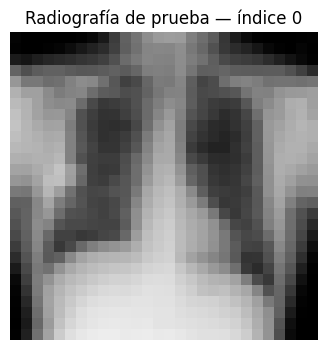

,Etiqueta,Real,Probabilidad,Umbral,Predicción,Resultado
0,atelectasis,0,0.0337,0.08,0,Verdadero negativo
1,cardiomegaly,0,0.0004,0.01,0,Verdadero negativo
2,effusion,0,0.0252,0.12,0,Verdadero negativo
3,infiltration,0,0.1287,0.11,1,Falso positivo
4,mass,0,0.1073,0.04,1,Falso positivo
5,nodule,0,0.1023,0.03,1,Falso positivo
6,pneumonia,0,0.0054,0.01,0,Verdadero negativo
7,pneumothorax,0,0.0455,0.03,1,Falso positivo
8,consolidation,0,0.0130,0.03,0,Verdadero negativo
9,edema,0,0.0016,0.02,0,Verdadero negativo


In [22]:
# Cambiar el índice para visualizar otra imagen de prueba
indice_demo = 0

# Recuperar la configuración guardada
with open(
    'resultados_cnn/metadatos_modelo_final.json',
    encoding='utf-8'
) as archivo:
    metadata_demo = json.load(archivo)

etiquetas_demo = metadata_demo['etiquetas']
umbrales_demo = np.asarray(metadata_demo['umbrales'])

# Predecir con el modelo recuperado del archivo
imagen_demo = X_test_cnn[indice_demo:indice_demo + 1]

probabilidades_demo = modelo_recuperado.predict(
    imagen_demo,
    verbose=0
)[0]

predicciones_demo = (
    probabilidades_demo >= umbrales_demo
).astype(int)

reales_demo = y_test_cnn[indice_demo].astype(int)

# Identificar el resultado por etiqueta
resultados_demo = []

for real, pred in zip(reales_demo, predicciones_demo):
    if real == 1 and pred == 1:
        resultado = 'Verdadero positivo'
    elif real == 0 and pred == 1:
        resultado = 'Falso positivo'
    elif real == 1 and pred == 0:
        resultado = 'Falso negativo'
    else:
        resultado = 'Verdadero negativo'

    resultados_demo.append(resultado)

plt.figure(figsize=(4, 4))
plt.imshow(
    X_test_full[indice_demo],
    cmap='gray',
    vmin=0,
    vmax=255
)
plt.title(f'Radiografía de prueba — índice {indice_demo}')
plt.axis('off')
plt.show()

tabla_demo = pd.DataFrame({
    'Etiqueta': etiquetas_demo,
    'Real': reales_demo,
    'Probabilidad': probabilidades_demo,
    'Umbral': umbrales_demo,
    'Predicción': predicciones_demo,
    'Resultado': resultados_demo
})

display(tabla_demo.round(4))

## Referencias y procedencia

- MedMNIST: https://medmnist.com/
- Guía de clase: Retina_CNN_II_2026.ipynb.
- BreastMNIST_2_CNN_CLAHE.ipynb: referencia para las arquitecturas VGG compacta, ResNet compacta y MobileNetV2.
- BreastMNIST_final-FINAL.ipynb: referencia para la organización CRISP-DM y la presentación del análisis y la evaluación.

Las arquitecturas, las salidas y la evaluación se adaptaron a la clasificación multietiqueta de ChestMNIST.